# Langkah 5 Anggota A — Ekstraksi Fitur Akustik

**Tujuan:** mengubah setiap rekaman hasil preprocessing menjadi 90 angka (fitur) yang menggambarkan cara orang berbicara. Tabel fitur inilah yang dipakai Anggota B untuk baseline dan simulated annealing.

**Fitur yang diekstrak (90)**

| Kelompok | Jumlah | Fitur | Yang digambarkan |
| --- | --- | --- | --- |
| `mfcc` | 26 | MFCC ke-1 sampai 13, mean dan std | Bentuk umum spektrum (warna suara) |
| `delta_mfcc` | 26 | Delta MFCC ke-1 sampai 13, mean dan std | Seberapa cepat warna suara berubah |
| `prosodi` | 6 | F0 mean, std, persentil 5, persentil 95, rentang, proporsi frame bersuara | Nada dasar dan intonasi |
| `energi` | 3 | RMS mean, std, max | Keras-pelan suara |
| `zcr` | 2 | Zero-crossing rate mean, std | Kekasaran / desis |
| `spektral` | 8 | Centroid, bandwidth, rolloff, flatness (mean, std) | Terang-gelap dan sebaran spektrum |
| `contrast` | 7 | Spectral contrast 7 pita (mean) | Beda puncak dan lembah spektrum |
| `chroma` | 12 | Chroma 12 kelas nada (mean) | Sebaran energi di kelas nada musik |

**Keputusan desain**

1. **MFCC ke-0 tidak dipakai.** Koefisien ke-0 pada dasarnya adalah energi total, jadi informasinya sudah diwakili fitur `rms_*`. Dengan begitu, perbedaan antara versi `none` dan `peak` terkumpul hanya di 3 fitur energi, sehingga perbandingan Anggota B lebih mudah ditafsirkan.
2. **F0 memakai persentil 5 dan 95, bukan nilai minimum dan maksimum.** Estimasi F0 kadang meleset satu oktaf pada beberapa frame; persentil lebih tahan terhadap kesalahan seperti itu.
3. **Dua versi tabel fitur:** `features_none.csv` (tanpa normalisasi) dan `features_peak.csv` (normalisasi puncak), sesuai keputusan 21 November 2026.
4. **F0 dihitung sekali untuk kedua versi**, karena F0 tidak berubah jika volume diubah (dibuktikan di Sel 4).
5. **Grafik deskriptif hanya memakai aktor 1–16** (rencana data train), supaya data validation dan test tidak "diintip" sebelum waktunya.
6. **Fitur non-energi dihitung dari salinan sinyal yang puncaknya dijadikan 1 secara internal.** Tanpa langkah ini, spectral flatness sedikit bergeser (±7%) pada frame yang sangat pelan karena librosa memakai batas bawah tetap. Dengan langkah ini, 87 fitur non-energi benar-benar tidak bergantung volume; hanya 3 fitur energi yang dihitung dari sinyal apa adanya.

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/processed/ravdess_16k_trim/` | Audio hasil langkah 4 |
| Input | `data/preprocess_log.csv`, `data/metadata.csv` | Dari langkah 4 dan 1 |
| Input | `src/preprocess.py` | Untuk normalisasi puncak |
| Output | `src/features.py` | Modul ekstraksi fitur; dipakai lagi di demo |
| Output | `config.json` | Parameter fitur (bagian `features`) |
| Output | `data/features/features_none.csv`, `features_peak.csv` | 1.440 baris × (5 kolom info + 90 fitur) |
| Output | `data/features/feature_names.csv` | Indeks, nama, kelompok, deskripsi, dan apakah fitur bergantung pada volume |
| Output | `figures/features/` | 2 grafik + `features_summary.txt` |
| Output | `docs/README_langkah5_ekstraksi_fitur.md` | Dokumentasi standar langkah ini |

**Prasyarat:** langkah 4 selesai. **Perkiraan waktu:** 10–30 menit (Sel 5 paling lama).

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

Sel ini berdiri sendiri, jadi aman dijalankan di sesi Colab baru. Jika hasil langkah 4 tidak ditemukan, sel berhenti dengan pesan yang jelas.

In [1]:
import os
import sys
import json
import time
import hashlib
import random
import importlib
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
PROC_DIR = os.path.join(DATA_DIR, 'processed', 'ravdess_16k_trim')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'features')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
MODULE_PATH = os.path.join(SRC_DIR, 'features.py')
CKPT_PATH = os.path.join(FEAT_DIR, '_checkpoint.pkl')
for d in [FEAT_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = {
    'metadata.csv': os.path.join(DATA_DIR, 'metadata.csv'),
    'preprocess_log.csv': os.path.join(DATA_DIR, 'preprocess_log.csv'),
    'audio hasil langkah 4': PROC_DIR,
    'src/preprocess.py': os.path.join(SRC_DIR, 'preprocess.py'),
    'config.json': CONFIG_PATH,
}
hilang = [k for k, p in wajib.items() if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError(f'Prasyarat tidak ditemukan: {hilang}. Jalankan langkah 4 dulu.')

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import preprocess as pp
importlib.reload(pp)

meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))
plog = pd.read_csv(os.path.join(DATA_DIR, 'preprocess_log.csv'))
with open(CONFIG_PATH, encoding='utf-8') as f:
    config = json.load(f)
PRE = config['preprocessing']
INFO_COLS = ['file', 'actor', 'gender', 'emotion', 'intensity']
EMOSI = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
TRAIN_ACTORS = list(range(1, 17))   # rencana split: aktor 1-16 = train

BIRU, ORANYE = '#2a78d6', '#eb6834'
TEKS, TEKS2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.edgecolor': TEKS2, 'axes.labelcolor': TEKS, 'text.color': TEKS,
    'xtick.color': TEKS2, 'ytick.color': TEKS2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

print('Prasyarat lengkap.')
print('File di metadata        :', len(meta))
print('File di preprocess_log  :', len(plog))
print('config_hash preprocessing:', PRE['config_hash'])

Mounted at /content/drive
Prasyarat lengkap.
File di metadata        : 1440
File di preprocess_log  : 1440
config_hash preprocessing: d930ff28cd


## Sel 2 — Parameter fitur dan `config.json`

Parameter disimpan ke `config.json` bagian `features`, tanpa mengubah bagian lain.

| Parameter | Nilai | Alasan |
| --- | --- | --- |
| `n_fft`, `hop_length` | 512, 160 sampel | Frame 32 ms bergeser 10 ms: standar analisis suara bicara |
| `n_mfcc`, `n_mels` | 13, 40 | MFCC ke-1 sampai 13 dari 40 pita mel, umum dipakai untuk suara bicara |
| `delta_width` | 9 frame | Bawaan librosa |
| `f0_fmin`, `f0_fmax` | 65–500 Hz | Mencakup nada suara laki-laki dan perempuan, termasuk saat berteriak |
| `f0_frame_length` | 1024 sampel (64 ms) | Cukup untuk menangkap minimal dua periode nada terendah (65 Hz) |
| `rolloff_percent` | 0,85 | Bawaan librosa |
| `contrast_fmin`, `contrast_n_bands` | 100 Hz, 6 pita | Menghasilkan 7 nilai dan tetap di bawah batas frekuensi 8 kHz |

In [2]:
FEATURE_CONFIG = {
    'sr': PRE['target_sr'],
    'n_fft': 512,
    'hop_length': 160,
    'n_mfcc': 13,
    'n_mels': 40,
    'delta_width': 9,
    'f0_fmin': 65.0,
    'f0_fmax': 500.0,
    'f0_frame_length': 1024,
    'rolloff_percent': 0.85,
    'contrast_fmin': 100.0,
    'contrast_n_bands': 6,
}
FEAT_HASH = hashlib.md5(json.dumps({**FEATURE_CONFIG, 'pre': PRE['config_hash']}, sort_keys=True).encode()).hexdigest()[:10]

config['features'] = {
    **FEATURE_CONFIG,
    'n_features': 90,
    'versions': ['none', 'peak'],
    'mfcc0_included': False,
    'f0_stats': 'mean, std, p05, p95, range (p95-p05), voiced_ratio',
    'preprocessing_hash': PRE['config_hash'],
    'version': '1.0',
    'config_hash': FEAT_HASH,
    'updated': datetime.now().strftime('%Y-%m-%d'),
    'owner': 'Anggota A',
}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print('Tersimpan:', CONFIG_PATH)
print(json.dumps(config['features'], indent=2))

Tersimpan: /content/drive/MyDrive/project07/config.json
{
  "sr": 16000,
  "n_fft": 512,
  "hop_length": 160,
  "n_mfcc": 13,
  "n_mels": 40,
  "delta_width": 9,
  "f0_fmin": 65.0,
  "f0_fmax": 500.0,
  "f0_frame_length": 1024,
  "rolloff_percent": 0.85,
  "contrast_fmin": 100.0,
  "contrast_n_bands": 6,
  "n_features": 90,
  "versions": [
    "none",
    "peak"
  ],
  "mfcc0_included": false,
  "f0_stats": "mean, std, p05, p95, range (p95-p05), voiced_ratio",
  "preprocessing_hash": "d930ff28cd",
  "version": "1.0",
  "config_hash": "0c3114fc78",
  "updated": "2026-11-21",
  "owner": "Anggota A"
}


## Sel 3 — Tulis modul `src/features.py`

Sama seperti langkah 4, aturan ekstraksi ditulis sebagai modul supaya demo Anggota C memakai rumus fitur yang persis sama.

| Isi modul | Kegunaan |
| --- | --- |
| `FEATURE_NAMES` | Daftar 90 nama fitur dalam urutan tetap |
| `FEATURE_TABLE` | Nama, kelompok, deskripsi, dan apakah bergantung pada volume |
| `extract_f0_features(y)` | 6 fitur prosodi dengan pyin |
| `extract_features(y, config, f0_feats)` | 90 fitur sebagai array; `f0_feats` dipakai ulang jika sudah dihitung |
| `extract_features_dict(...)` | Sama, tetapi dalam bentuk dict `{nama: nilai}` |

In [3]:
%%writefile {MODULE_PATH}
"""
features.py - Ekstraksi 90 fitur akustik untuk Proyek 07
(Finding the Best Acoustic Features).

Penanggung jawab : Anggota A
Versi            : 1.0 (22 November 2026)

Dipakai oleh:
  - Langkah 5 (Anggota A): membuat features_none.csv dan features_peak.csv
  - Demo Gradio (Anggota C): menghitung fitur rekaman pengguna
Masukan fungsi adalah audio yang SUDAH dipreprocessing dengan
src/preprocess.py (mono, 16 kHz, trim hening).

Setiap fitur adalah ringkasan (rata-rata, simpangan baku, dsb.) dari nilai
per frame. Frame: n_fft = 512 sampel (32 ms), hop = 160 sampel (10 ms).

Kelompok fitur (total 90):
  mfcc        26  MFCC ke-1..13, mean dan std (koefisien ke-0 tidak dipakai)
  delta_mfcc  26  delta MFCC ke-1..13, mean dan std
  prosodi      6  F0 (pyin): mean, std, persentil 5, persentil 95,
                  rentang (p95 - p5), proporsi frame bersuara
  energi       3  RMS: mean, std, max
  zcr          2  zero-crossing rate: mean, std
  spektral     8  centroid, bandwidth, rolloff, flatness: mean dan std
  contrast     7  spectral contrast 7 pita: mean
  chroma      12  chroma 12 kelas nada: mean

Hanya 3 fitur energi (rms_*) yang bergantung pada level suara absolut.
Fitur lain dihitung dari salinan sinyal yang dinormalisasi secara internal
(puncak = 1), sehingga benar-benar tidak berubah jika sinyal dikalikan
konstanta. Tanpa langkah ini, spectral flatness sedikit bergeser pada frame
yang sangat pelan karena librosa memakai batas bawah tetap (amin = 1e-10).
Karena itu F0 (bagian paling lambat) cukup dihitung sekali untuk semua
versi normalisasi.
"""

import numpy as np
import librosa

FEATURES_VERSION = '1.0'

DEFAULT_CONFIG = {
    'sr': 16000,
    'n_fft': 512,
    'hop_length': 160,
    'n_mfcc': 13,          # MFCC ke-1..13 (ke-0 dibuang)
    'n_mels': 40,
    'delta_width': 9,
    'f0_fmin': 65.0,
    'f0_fmax': 500.0,
    'f0_frame_length': 1024,
    'rolloff_percent': 0.85,
    'contrast_fmin': 100.0,
    'contrast_n_bands': 6,  # menghasilkan 7 nilai
}

CHROMA_LABELS = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']


def _feature_table():
    """Daftar (nama, kelompok, deskripsi, bergantung_skala) untuk 90 fitur."""
    rows = []
    for stat in ('mean', 'std'):
        for i in range(1, 14):
            rows.append((f'mfcc{i:02d}_{stat}', 'mfcc',
                         f'MFCC koefisien ke-{i}, {stat} antarframe', False))
    for stat in ('mean', 'std'):
        for i in range(1, 14):
            rows.append((f'dmfcc{i:02d}_{stat}', 'delta_mfcc',
                         f'Delta (laju perubahan) MFCC ke-{i}, {stat} antarframe', False))
    rows += [
        ('f0_mean', 'prosodi', 'Rata-rata F0 (nada dasar) frame bersuara, Hz', False),
        ('f0_std', 'prosodi', 'Simpangan baku F0 frame bersuara, Hz', False),
        ('f0_p05', 'prosodi', 'Persentil 5 F0 frame bersuara, Hz', False),
        ('f0_p95', 'prosodi', 'Persentil 95 F0 frame bersuara, Hz', False),
        ('f0_range', 'prosodi', 'Rentang F0 = p95 - p05, Hz', False),
        ('voiced_ratio', 'prosodi', 'Proporsi frame bersuara (0-1)', False),
        ('rms_mean', 'energi', 'Rata-rata energi RMS antarframe', True),
        ('rms_std', 'energi', 'Simpangan baku energi RMS antarframe', True),
        ('rms_max', 'energi', 'Energi RMS frame terbesar', True),
        ('zcr_mean', 'zcr', 'Rata-rata zero-crossing rate', False),
        ('zcr_std', 'zcr', 'Simpangan baku zero-crossing rate', False),
    ]
    for name, desc in [('centroid', 'Spectral centroid (pusat massa spektrum), Hz'),
                       ('bandwidth', 'Spectral bandwidth (lebar sebaran spektrum), Hz'),
                       ('rolloff', 'Spectral rolloff (frekuensi batas 85% energi), Hz'),
                       ('flatness', 'Spectral flatness (0 = bernada, 1 = seperti noise)')]:
        rows.append((f'{name}_mean', 'spektral', f'{desc}, mean', False))
        rows.append((f'{name}_std', 'spektral', f'{desc}, std', False))
    for i in range(1, 8):
        rows.append((f'contrast{i}_mean', 'contrast',
                     f'Spectral contrast pita ke-{i} (selisih puncak-lembah), mean', False))
    for i, lab in enumerate(CHROMA_LABELS, start=1):
        rows.append((f'chroma{i:02d}_mean', 'chroma',
                     f'Chroma kelas nada {lab}, mean', False))
    return rows


FEATURE_TABLE = _feature_table()
FEATURE_NAMES = [r[0] for r in FEATURE_TABLE]
assert len(FEATURE_NAMES) == 90, len(FEATURE_NAMES)


def _cfg(config):
    merged = dict(DEFAULT_CONFIG)
    if config:
        merged.update({k: v for k, v in config.items() if k in DEFAULT_CONFIG})
    return merged


def _unit_peak(y):
    """Salinan sinyal dengan puncak 1 (untuk fitur yang tidak boleh bergantung volume)."""
    peak = float(np.max(np.abs(y))) if len(y) else 0.0
    return (y / peak).astype(np.float32) if peak > 0 else np.asarray(y, dtype=np.float32)


def extract_f0_features(y, config=None):
    """Hitung 6 fitur prosodi dengan pyin.

    Frame tanpa nada (unvoiced) diabaikan. Jika tidak ada frame bersuara,
    semua statistik F0 = 0 dan voiced_ratio = 0.

    Returns
    -------
    dict berisi f0_mean, f0_std, f0_p05, f0_p95, f0_range, voiced_ratio
    """
    c = _cfg(config)
    f0, voiced, _ = librosa.pyin(
        _unit_peak(np.asarray(y, dtype=np.float32)), fmin=c['f0_fmin'], fmax=c['f0_fmax'], sr=c['sr'],
        frame_length=c['f0_frame_length'], hop_length=c['hop_length'])
    ok = voiced & np.isfinite(f0)
    ratio = float(ok.mean()) if len(ok) else 0.0
    if ok.sum() == 0:
        return {'f0_mean': 0.0, 'f0_std': 0.0, 'f0_p05': 0.0, 'f0_p95': 0.0,
                'f0_range': 0.0, 'voiced_ratio': ratio}
    v = f0[ok]
    p05, p95 = np.percentile(v, [5, 95])
    return {'f0_mean': float(v.mean()), 'f0_std': float(v.std()),
            'f0_p05': float(p05), 'f0_p95': float(p95),
            'f0_range': float(p95 - p05), 'voiced_ratio': ratio}


def extract_features(y, config=None, f0_feats=None):
    """Hitung 90 fitur dari audio yang sudah dipreprocessing.

    Parameters
    ----------
    y : np.ndarray
        Audio mono 16 kHz hasil src/preprocess.py.
    config : dict, opsional
        Mengganti nilai DEFAULT_CONFIG.
    f0_feats : dict, opsional
        Hasil extract_f0_features untuk audio yang sama. Jika diberikan,
        pyin tidak dihitung ulang (F0 tidak bergantung pada volume).

    Returns
    -------
    np.ndarray (float64) berisi 90 nilai, urutannya sesuai FEATURE_NAMES
    """
    c = _cfg(config)
    sr, n_fft, hop = c['sr'], c['n_fft'], c['hop_length']
    y = np.asarray(y, dtype=np.float32)
    yu = _unit_peak(y)   # untuk semua fitur selain energi
    out = {}

    mfcc = librosa.feature.mfcc(y=yu, sr=sr, n_mfcc=c['n_mfcc'] + 1, n_mels=c['n_mels'],
                                n_fft=n_fft, hop_length=hop)[1:]
    n_frames = mfcc.shape[1]
    width = min(c['delta_width'], n_frames if n_frames % 2 == 1 else n_frames - 1)
    if width >= 3:
        dmfcc = librosa.feature.delta(mfcc, width=width)
    else:
        dmfcc = np.zeros_like(mfcc)
    for i in range(c['n_mfcc']):
        out[f'mfcc{i + 1:02d}_mean'] = mfcc[i].mean()
        out[f'mfcc{i + 1:02d}_std'] = mfcc[i].std()
        out[f'dmfcc{i + 1:02d}_mean'] = dmfcc[i].mean()
        out[f'dmfcc{i + 1:02d}_std'] = dmfcc[i].std()

    out.update(f0_feats if f0_feats is not None else extract_f0_features(yu, c))

    rms = librosa.feature.rms(y=y, frame_length=n_fft, hop_length=hop)[0]
    out['rms_mean'], out['rms_std'], out['rms_max'] = rms.mean(), rms.std(), rms.max()

    zcr = librosa.feature.zero_crossing_rate(yu, frame_length=n_fft, hop_length=hop)[0]
    out['zcr_mean'], out['zcr_std'] = zcr.mean(), zcr.std()

    spek = {
        'centroid': librosa.feature.spectral_centroid(y=yu, sr=sr, n_fft=n_fft, hop_length=hop)[0],
        'bandwidth': librosa.feature.spectral_bandwidth(y=yu, sr=sr, n_fft=n_fft, hop_length=hop)[0],
        'rolloff': librosa.feature.spectral_rolloff(y=yu, sr=sr, n_fft=n_fft, hop_length=hop,
                                                    roll_percent=c['rolloff_percent'])[0],
        'flatness': librosa.feature.spectral_flatness(y=yu, n_fft=n_fft, hop_length=hop)[0],
    }
    for name, v in spek.items():
        out[f'{name}_mean'], out[f'{name}_std'] = v.mean(), v.std()

    contrast = librosa.feature.spectral_contrast(y=yu, sr=sr, n_fft=n_fft, hop_length=hop,
                                                 fmin=c['contrast_fmin'], n_bands=c['contrast_n_bands'])
    for i in range(contrast.shape[0]):
        out[f'contrast{i + 1}_mean'] = contrast[i].mean()

    chroma = librosa.feature.chroma_stft(y=yu, sr=sr, n_fft=n_fft, hop_length=hop)
    for i in range(12):
        out[f'chroma{i + 1:02d}_mean'] = chroma[i].mean()

    return np.array([float(out[n]) for n in FEATURE_NAMES], dtype=np.float64)


def extract_features_dict(y, config=None, f0_feats=None):
    """Sama seperti extract_features, tetapi mengembalikan dict {nama: nilai}."""
    return dict(zip(FEATURE_NAMES, extract_features(y, config, f0_feats)))


Writing /content/drive/MyDrive/project07/src/features.py


In [4]:
import features as ft
importlib.reload(ft)
print('Modul dimuat dari:', ft.__file__)
print('Versi:', ft.FEATURES_VERSION, '| jumlah fitur:', len(ft.FEATURE_NAMES))

Modul dimuat dari: /content/drive/MyDrive/project07/src/features.py
Versi: 1.0 | jumlah fitur: 90


## Sel 4 — Uji modul sebelum dipakai

1. **Nada buatan 180 Hz** (dengan harmonik, menyerupai suara): F0 terukur harus sekitar 180 Hz dan hampir semua frame terdeteksi bersuara.
2. **Noise acak:** hampir tidak ada frame yang terdeteksi bersuara.
3. **Audio sangat pendek (0,05 s):** tetap menghasilkan 90 angka tanpa NaN (penting untuk demo).
4. **Sifat kunci pada data asli (5 file):** jika volume dikecilkan 10 kali, 87 fitur non-energi tidak berubah dan 3 fitur energi tepat mengecil 10 kali. Inilah dasar menghitung F0 sekali untuk kedua versi.

Catatan: panggilan `pyin` pertama butuh beberapa detik karena kodenya dikompilasi dulu; panggilan berikutnya jauh lebih cepat.

In [5]:
hasil_uji = []
def uji(judul, kondisi, detail=''):
    tanda = 'OK ' if kondisi else 'GAGAL'
    hasil_uji.append((judul, bool(kondisi)))
    print(f'[{tanda}] {judul}' + (f' — {detail}' if detail else ''))

sr = FEATURE_CONFIG['sr']
t = np.arange(int(sr * 1.9)) / sr
f0_buatan = 180 * (1 + 0.05 * np.sin(2 * np.pi * 2 * t))
fase = 2 * np.pi * np.cumsum(f0_buatan) / sr
nada = (sum(np.sin(k * fase) / k for k in range(1, 9)) * 0.2).astype(np.float32)
d = ft.extract_features_dict(nada, FEATURE_CONFIG)
uji('F0 nada buatan ±180 Hz', abs(d['f0_mean'] - 180) < 5, f"{d['f0_mean']:.1f} Hz")
uji('Nada buatan terdeteksi bersuara', d['voiced_ratio'] > 0.8, f"voiced_ratio {d['voiced_ratio']:.2f}")

noise = (0.01 * np.random.default_rng(1).normal(size=sr)).astype(np.float32)
vr = ft.extract_features_dict(noise, FEATURE_CONFIG)['voiced_ratio']
uji('Noise hampir tidak terdeteksi bersuara', vr < 0.2, f'voiced_ratio {vr:.2f}')

pendek = ft.extract_features(nada[:int(0.05 * sr)], FEATURE_CONFIG)
uji('Audio 0,05 s menghasilkan 90 angka tanpa NaN', len(pendek) == 90 and np.isfinite(pendek).all())

skala = np.array([r[3] for r in ft.FEATURE_TABLE])
random.seed(11)
lolos_inv, lolos_rms = True, True
for f in random.sample(plog['file'].tolist(), min(5, len(plog))):
    y, _ = sf.read(os.path.join(PROC_DIR, f), dtype='float32')
    a = ft.extract_features(y, FEATURE_CONFIG)
    b = ft.extract_features(y * 0.1, FEATURE_CONFIG)
    lolos_inv &= np.allclose(a[~skala], b[~skala], rtol=1e-3, atol=1e-4)
    lolos_rms &= np.allclose(b[skala] / a[skala], 0.1, rtol=1e-4)
uji('87 fitur non-energi tidak berubah saat volume diubah (5 file asli)', lolos_inv)
uji('3 fitur energi ikut berubah tepat 10 kali (5 file asli)', lolos_rms)

if not all(ok for _, ok in hasil_uji):
    raise RuntimeError('Ada uji yang GAGAL. Jangan lanjut; kirim output sel ini ke kelompok.')
print('\nSemua uji lolos. Aman untuk lanjut ke Sel 5.')

[OK ] F0 nada buatan ±180 Hz — 180.4 Hz
[OK ] Nada buatan terdeteksi bersuara — voiced_ratio 1.00
[OK ] Noise hampir tidak terdeteksi bersuara — voiced_ratio 0.00
[OK ] Audio 0,05 s menghasilkan 90 angka tanpa NaN
[OK ] 87 fitur non-energi tidak berubah saat volume diubah (5 file asli)
[OK ] 3 fitur energi ikut berubah tepat 10 kali (5 file asli)

Semua uji lolos. Aman untuk lanjut ke Sel 5.


## Sel 5 — Ekstraksi fitur semua file (dua versi)

Untuk setiap file:

1. Muat audio hasil langkah 4 (versi tanpa normalisasi).
2. Hitung F0 sekali dengan pyin.
3. Hitung 90 fitur untuk versi `none`.
4. Normalisasi puncak dengan `pp.normalize(y, 'peak', 0.99)`, lalu hitung 90 fitur versi `peak` dengan F0 yang sama.

**Checkpoint:** setiap 100 file, hasil sementara disimpan ke `data/features/_checkpoint.pkl`. Jika Colab terputus, jalankan ulang Sel 1–3 lalu sel ini; proses akan melanjutkan dari file terakhir, tidak mengulang dari awal. Checkpoint dihapus otomatis setelah selesai.

Jika kedua tabel fitur sudah ada dengan parameter yang sama, proses dilewati. Butuh sekitar 5–25 menit.

In [6]:
META_PATH = os.path.join(FEAT_DIR, 'features_meta.json')
OUT_NONE = os.path.join(FEAT_DIR, 'features_none.csv')
OUT_PEAK = os.path.join(FEAT_DIR, 'features_peak.csv')

def sudah_selesai():
    if not (os.path.exists(META_PATH) and os.path.exists(OUT_NONE) and os.path.exists(OUT_PEAK)):
        return False
    with open(META_PATH) as f:
        return json.load(f).get('config_hash') == FEAT_HASH

if sudah_selesai():
    print('Tabel fitur sudah ada dengan parameter yang sama; ekstraksi dilewati.')
else:
    if os.path.exists(CKPT_PATH):
        ckpt = pd.read_pickle(CKPT_PATH)
        if ckpt.get('config_hash') != FEAT_HASH:
            ckpt = {'config_hash': FEAT_HASH, 'none': {}, 'peak': {}, 'gagal': {}}
        else:
            print(f"Melanjutkan dari checkpoint: {len(ckpt['none'])} file sudah selesai.")
    else:
        ckpt = {'config_hash': FEAT_HASH, 'none': {}, 'peak': {}, 'gagal': {}}

    sisa = [f for f in meta['file'] if f not in ckpt['none']]
    mulai = time.time()
    for i, f in enumerate(sisa, start=1):
        try:
            y, _ = sf.read(os.path.join(PROC_DIR, f), dtype='float32')
            f0 = ft.extract_f0_features(y, FEATURE_CONFIG)
            ckpt['none'][f] = ft.extract_features(y, FEATURE_CONFIG, f0_feats=f0)
            y_peak = pp.normalize(y, 'peak', PRE['peak_target'])
            ckpt['peak'][f] = ft.extract_features(y_peak, FEATURE_CONFIG, f0_feats=f0)
        except Exception as e:
            ckpt['gagal'][f] = str(e)
        if i % 100 == 0 or i == len(sisa):
            pd.to_pickle(ckpt, CKPT_PATH)
            laju = (time.time() - mulai) / i
            print(f"  {len(ckpt['none'])} / {len(meta)} file | sisa ±{laju * (len(sisa) - i) / 60:.1f} menit")

    if ckpt['gagal']:
        print('GAGAL:', len(ckpt['gagal']))
        for f, e in list(ckpt['gagal'].items())[:10]:
            print('  ', f, '→', e)

    for versi, path in [('none', OUT_NONE), ('peak', OUT_PEAK)]:
        X = pd.DataFrame([ckpt[versi][f] for f in meta['file'] if f in ckpt[versi]], columns=ft.FEATURE_NAMES)
        info = meta.loc[meta['file'].isin(ckpt[versi]), INFO_COLS].reset_index(drop=True)
        pd.concat([info, X], axis=1).to_csv(path, index=False)
        print('Tersimpan:', path)

    pd.DataFrame([{'index': i, 'name': n, 'group': g, 'description': d, 'scale_dependent': s}
                  for i, (n, g, d, s) in enumerate(ft.FEATURE_TABLE)]).to_csv(
        os.path.join(FEAT_DIR, 'feature_names.csv'), index=False)
    with open(META_PATH, 'w') as f:
        json.dump({'config_hash': FEAT_HASH, 'created': datetime.now().strftime('%Y-%m-%d %H:%M'),
                   'n_files': len(ckpt['none']), 'n_failed': len(ckpt['gagal'])}, f, indent=2)
    if not ckpt['gagal']:
        os.remove(CKPT_PATH)
    print('Tersimpan:', os.path.join(FEAT_DIR, 'feature_names.csv'))

fn = pd.read_csv(OUT_NONE)
fp = pd.read_csv(OUT_PEAK)
names = pd.read_csv(os.path.join(FEAT_DIR, 'feature_names.csv'))
print(f'\nfeatures_none.csv: {fn.shape[0]} baris × {fn.shape[1]} kolom')
print(f'features_peak.csv: {fp.shape[0]} baris × {fp.shape[1]} kolom')
fn.head()

  100 / 1440 file | sisa ±25.7 menit
  200 / 1440 file | sisa ±24.5 menit
  300 / 1440 file | sisa ±22.4 menit
  400 / 1440 file | sisa ±20.8 menit
  500 / 1440 file | sisa ±18.7 menit
  600 / 1440 file | sisa ±16.6 menit
  700 / 1440 file | sisa ±14.5 menit
  800 / 1440 file | sisa ±12.4 menit
  900 / 1440 file | sisa ±10.4 menit
  1000 / 1440 file | sisa ±8.4 menit
  1100 / 1440 file | sisa ±6.5 menit
  1200 / 1440 file | sisa ±4.6 menit
  1300 / 1440 file | sisa ±2.7 menit
  1400 / 1440 file | sisa ±0.8 menit
  1440 / 1440 file | sisa ±0.0 menit
Tersimpan: /content/drive/MyDrive/project07/data/features/features_none.csv
Tersimpan: /content/drive/MyDrive/project07/data/features/features_peak.csv
Tersimpan: /content/drive/MyDrive/project07/data/features/feature_names.csv

features_none.csv: 1440 baris × 95 kolom
features_peak.csv: 1440 baris × 95 kolom


,file,actor,gender,emotion,intensity,mfcc01_mean,mfcc02_mean,mfcc03_mean,mfcc04_mean,mfcc05_mean,...,chroma03_mean,chroma04_mean,chroma05_mean,chroma06_mean,chroma07_mean,chroma08_mean,chroma09_mean,chroma10_mean,chroma11_mean,chroma12_mean
0,Actor_01/03-01-01-01-01-01-01.wav,1,male,neutral,normal,69.740967,3.155350,22.222437,7.964320,-0.244235,...,0.461242,0.436548,0.450247,0.432708,0.456146,0.509465,0.550682,0.573083,0.533134,0.528326
1,Actor_01/03-01-01-01-01-02-01.wav,1,male,neutral,normal,66.926826,4.899268,25.001829,6.514272,0.910886,...,0.453084,0.403487,0.461922,0.458982,0.440064,0.497906,0.557450,0.587525,0.575048,0.567368
2,Actor_01/03-01-01-01-02-01-01.wav,1,male,neutral,normal,69.776863,6.760493,21.699930,5.089364,2.606738,...,0.506141,0.506542,0.419672,0.390340,0.429685,0.509713,0.526689,0.500431,0.480084,0.535970
3,Actor_01/03-01-01-01-02-02-01.wav,1,male,neutral,normal,66.566566,9.330391,22.212437,6.541668,3.831398,...,0.462140,0.450360,0.490144,0.500060,0.504687,0.535774,0.577923,0.560597,0.537299,0.545620
4,Actor_01/03-01-02-01-01-01-01.wav,1,male,calm,normal,65.367416,7.695789,20.803802,7.578409,1.049309,...,0.499368,0.467081,0.472308,0.484801,0.468084,0.467038,0.526920,0.577076,0.591412,0.545457


## Sel 6 — Verifikasi hasil

| No | Pemeriksaan | Mengapa |
| --- | --- | --- |
| 1 | Kedua tabel berisi 1.440 baris | Tidak ada file terlewat |
| 2 | 90 kolom fitur dengan urutan sama seperti `feature_names.csv` | Indeks fitur konsisten untuk simulated annealing |
| 3 | Tidak ada NaN atau nilai tak hingga | Model tidak bisa memproses nilai kosong |
| 4 | Kolom info (file, aktor, gender, emosi, intensitas) sama dengan `metadata.csv` | Label tidak tertukar |
| 5 | 87 fitur non-energi identik antara versi `none` dan `peak` | Perbedaan versi hanya di fitur energi |
| 6 | Rasio fitur energi `peak`/`none` = faktor normalisasi di `preprocess_log.csv` | Normalisasi diterapkan dengan benar |
| 7 | 5 file acak diekstrak ulang = hasil tersimpan | Hasil bisa diulang persis |
| 8 | F0 file bersuara di rentang 65–500 Hz dan `voiced_ratio` di 0–1 | Nilai masuk akal |
| 9 | Tidak ada fitur yang nilainya sama untuk semua file | Fitur konstan tidak berguna bagi model |

In [7]:
laporan = []
def cek(judul, kondisi, detail=''):
    tanda = 'OK ' if kondisi else 'CEK'
    teks = f'[{tanda}] {judul}' + (f' — {detail}' if detail else '')
    laporan.append(teks)
    print(teks)

F = ft.FEATURE_NAMES
skala = names['scale_dependent'].astype(bool).values
cek('Kedua tabel berisi semua file', len(fn) == len(meta) and len(fp) == len(meta), f'{len(fn)} dan {len(fp)} baris')
cek('90 kolom fitur sesuai feature_names.csv',
    list(fn.columns[len(INFO_COLS):]) == list(names['name']) == F and list(fp.columns) == list(fn.columns))
bersih = np.isfinite(fn[F].values).all() and np.isfinite(fp[F].values).all()
cek('Tidak ada NaN / tak hingga', bersih)
cek('Kolom info sama dengan metadata.csv',
    fn[INFO_COLS].equals(meta[INFO_COLS]) and fp[INFO_COLS].equals(meta[INFO_COLS]))

A, B = fn[F].values, fp[F].values
cek('87 fitur non-energi identik antara none dan peak', np.allclose(A[:, ~skala], B[:, ~skala], rtol=1e-3, atol=1e-4),
    f'selisih relatif maks {np.max(np.abs(A[:, ~skala] - B[:, ~skala]) / (np.abs(A[:, ~skala]) + 1e-4)):.1e}')
gain = fn[['file']].merge(plog[['file', 'peak_gain']], on='file')['peak_gain'].values
rasio = B[:, skala] / A[:, skala]
cek('Rasio energi peak/none = faktor normalisasi', np.allclose(rasio, gain[:, None], rtol=1e-3),
    f'selisih relatif maks {np.max(np.abs(rasio / gain[:, None] - 1)):.1e}')

random.seed(5)
sama = 0
for f in random.sample(meta['file'].tolist(), min(5, len(meta))):
    y, _ = sf.read(os.path.join(PROC_DIR, f), dtype='float32')
    ulang = ft.extract_features(y, FEATURE_CONFIG)
    sama += int(np.allclose(ulang, fn.loc[fn['file'] == f, F].values[0], rtol=1e-6, atol=1e-8))
cek('Ekstraksi ulang 5 file acak = hasil tersimpan', sama == 5 or sama == min(5, len(meta)), f'{sama} file sama')

bersuara = fn['voiced_ratio'] > 0
f0_ok = fn.loc[bersuara, 'f0_mean'].between(65, 500).all() and fn['voiced_ratio'].between(0, 1).all()
cek('F0 di 65–500 Hz dan voiced_ratio di 0–1', f0_ok,
    f"F0 mean {fn.loc[bersuara, 'f0_mean'].min():.0f}–{fn.loc[bersuara, 'f0_mean'].max():.0f} Hz; file tanpa frame bersuara: {int((~bersuara).sum())}")
konstan = [n for n in F if fn[n].std() == 0]
cek('Tidak ada fitur konstan', len(konstan) == 0, f'{len(konstan)} fitur konstan' + (f': {konstan}' if konstan else ''))

[OK ] Kedua tabel berisi semua file — 1440 dan 1440 baris
[OK ] 90 kolom fitur sesuai feature_names.csv
[OK ] Tidak ada NaN / tak hingga
[OK ] Kolom info sama dengan metadata.csv
[OK ] 87 fitur non-energi identik antara none dan peak — selisih relatif maks 5.6e-04
[OK ] Rasio energi peak/none = faktor normalisasi — selisih relatif maks 3.4e-07
[OK ] Ekstraksi ulang 5 file acak = hasil tersimpan — 5 file sama
[OK ] F0 di 65–500 Hz dan voiced_ratio di 0–1 — F0 mean 78–492 Hz; file tanpa frame bersuara: 5
[OK ] Tidak ada fitur konstan — 0 fitur konstan


## Sel 7 — Grafik deskriptif

Kedua grafik hanya memakai **aktor 1–16** (rencana data train) dan versi `none`. Tujuannya mengenal fitur, **bukan** memilih fitur; pemilihan fitur adalah tugas simulated annealing Anggota B.

1. **F0 per emosi dan gender:** apakah nada dasar berbeda antaremosi, dan seberapa besar pengaruh gender.
2. **Profil fitur per emosi (heatmap):** setiap kotak adalah rata-rata fitur untuk satu emosi, dalam satuan simpangan baku dari rata-rata semua file (z-score). Merah = lebih tinggi dari rata-rata, biru = lebih rendah. Kolom yang warnanya sangat berbeda antarbaris menandakan fitur yang kemungkinan berguna untuk membedakan emosi.

File aktor 1-16: 960


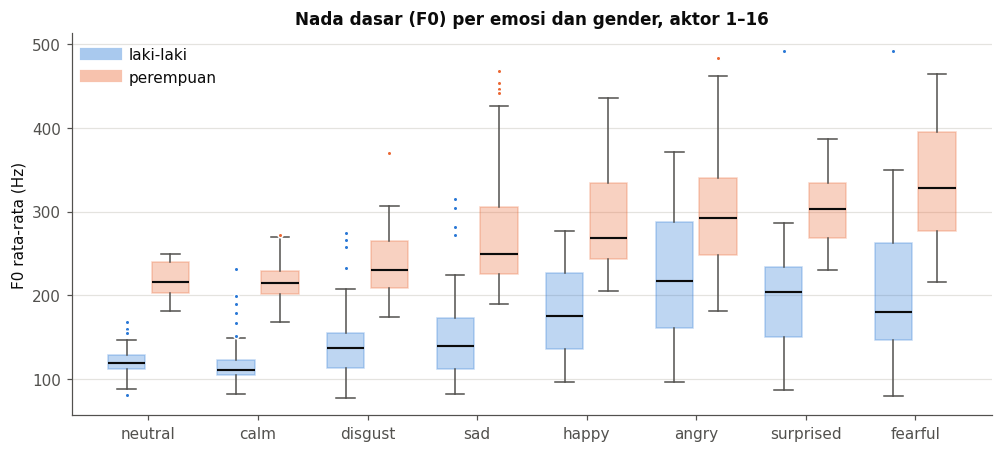

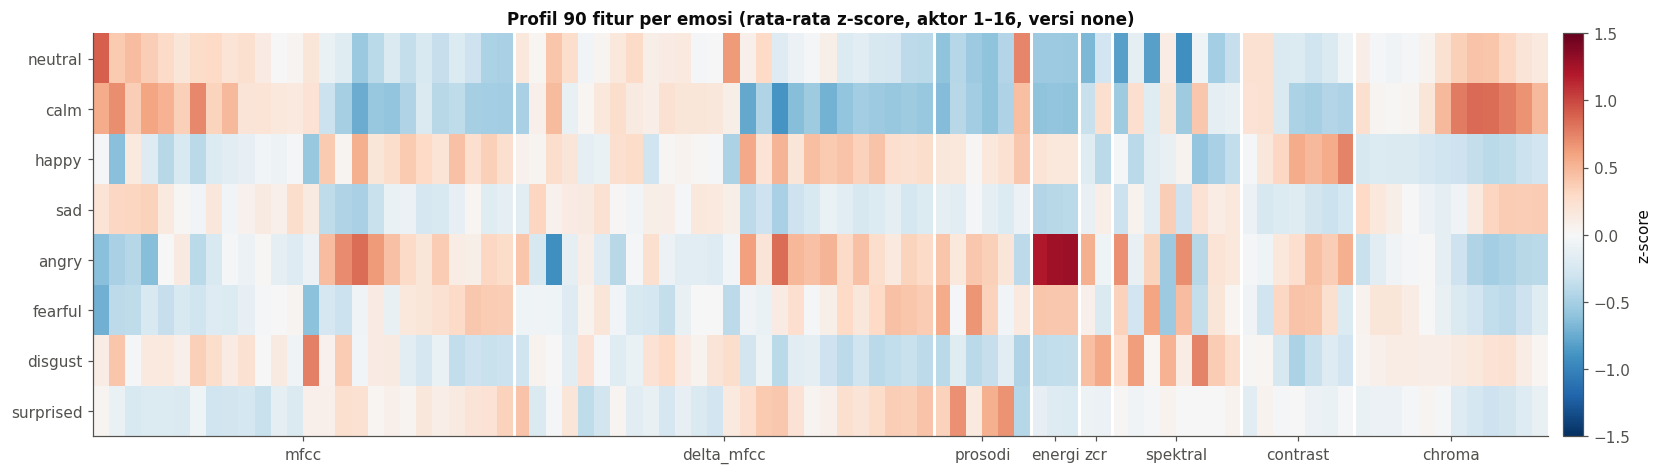

15 fitur dengan perbedaan rata-rata antaremosi terbesar (deskriptif, aktor 1-16):


,kelompok,selisih z antaremosi
rms_max,energi,1.88
rms_std,energi,1.85
rms_mean,energi,1.80
dmfcc04_std,delta_mfcc,1.72
mfcc01_mean,mfcc,1.62
rolloff_mean,spektral,1.61
mfcc04_std,mfcc,1.57
centroid_mean,spektral,1.51
bandwidth_mean,spektral,1.40
dmfcc03_mean,delta_mfcc,1.39


In [8]:
tr = fn[fn['actor'].isin(TRAIN_ACTORS)].copy()
print('File aktor 1-16:', len(tr))

urut = tr.groupby('emotion')['f0_mean'].median().reindex(EMOSI).sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
pos = np.arange(len(urut))
for off, g, warna, label in [(-0.2, 'male', BIRU, 'laki-laki'), (0.2, 'female', ORANYE, 'perempuan')]:
    data = [tr.loc[(tr['emotion'] == e) & (tr['gender'] == g) & (tr['voiced_ratio'] > 0), 'f0_mean'] for e in urut]
    bp = ax.boxplot(data, positions=pos + off, widths=0.34, patch_artist=True,
                    medianprops=dict(color=TEKS, linewidth=1.4),
                    flierprops=dict(marker='o', markersize=3, markerfacecolor=warna, markeredgecolor='white'),
                    whiskerprops=dict(color=TEKS2), capprops=dict(color=TEKS2))
    for kotak in bp['boxes']:
        kotak.set(facecolor=warna, alpha=0.3, edgecolor=warna)
    ax.plot([], [], color=warna, linewidth=8, alpha=0.4, label=label)
ax.set_xticks(pos, urut)
ax.set_ylabel('F0 rata-rata (Hz)')
ax.set_title('Nada dasar (F0) per emosi dan gender, aktor 1–16')
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='x', visible=False)
fig.savefig(os.path.join(FIG_DIR, 'feat_01_f0_per_emosi_gender.png'))
plt.show()

z = (tr[F] - tr[F].mean()) / tr[F].std().replace(0, 1)
prof = z.groupby(tr['emotion']).mean().reindex(EMOSI)
fig, ax = plt.subplots(figsize=(15, 4.2), layout='constrained')
im = ax.imshow(prof.values, aspect='auto', cmap='RdBu_r', vmin=-1.5, vmax=1.5)
ax.set_yticks(range(len(EMOSI)), EMOSI)
grup = names['group'].tolist()
batas = [i for i in range(1, len(grup)) if grup[i] != grup[i - 1]]
for b in batas:
    ax.axvline(b - 0.5, color='white', linewidth=2)
awal = [0] + batas
akhir = batas + [len(grup)]
ax.set_xticks([(a + b - 1) / 2 for a, b in zip(awal, akhir)], [grup[a] for a in awal])
ax.grid(False)
ax.set_title('Profil 90 fitur per emosi (rata-rata z-score, aktor 1–16, versi none)')
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
cb.set_label('z-score')
fig.savefig(os.path.join(FIG_DIR, 'feat_02_profil_fitur_per_emosi.png'))
plt.show()

beda = (prof.max() - prof.min()).sort_values(ascending=False)
top = pd.DataFrame({'kelompok': names.set_index('name').loc[beda.index[:15], 'group'],
                    'selisih z antaremosi': beda.iloc[:15].round(2)})
print('15 fitur dengan perbedaan rata-rata antaremosi terbesar (deskriptif, aktor 1-16):')
display(top)

**Catatan penting:** daftar 15 fitur di atas hanyalah gambaran awal dan **tidak boleh dipakai untuk memilih fitur**. Ukuran ini melihat setiap fitur secara terpisah dan mengabaikan korelasi antarfitur. Pemilihan fitur dilakukan oleh simulated annealing (Anggota B), sedangkan filter method resmi (mutual information) dihitung di langkah 10 dengan data train saja. Daftar ini berguna nanti untuk dibandingkan dengan fitur yang dipilih SA.

## Sel 8 — Ringkasan dan dokumentasi standar

Sel ini menyimpan `figures/features/features_summary.txt` dan `docs/README_langkah5_ekstraksi_fitur.md`.

In [9]:
tgl = datetime.now().strftime('%Y-%m-%d')
n_ok = sum(t.startswith('[OK') for t in laporan)
per_grup = names['group'].value_counts().reindex(names['group'].unique())
f0_g = tr[tr['voiced_ratio'] > 0].groupby('gender')['f0_mean'].median()
ringkas = [
    f'Ringkasan ekstraksi fitur (langkah 5, {tgl})',
    f'config_hash fitur: {FEAT_HASH} | config_hash preprocessing: {PRE["config_hash"]}',
    '',
    f'File: {len(fn)} | fitur: {len(F)} | versi: none, peak',
    'Fitur per kelompok: ' + ', '.join(f'{g} {n}' for g, n in per_grup.items()),
    f'Fitur bergantung volume: {int(skala.sum())} ({", ".join(names.loc[skala, "name"])})',
    f"File tanpa frame bersuara: {int((fn['voiced_ratio'] == 0).sum())}",
    f"voiced_ratio median: {fn['voiced_ratio'].median():.2f}",
    f"F0 rata-rata (median, aktor 1-16): laki-laki {f0_g.get('male', float('nan')):.0f} Hz, perempuan {f0_g.get('female', float('nan')):.0f} Hz",
    '',
    '15 fitur dengan perbedaan rata-rata antaremosi terbesar (deskriptif, aktor 1-16, bukan seleksi):',
] + [f'  {i + 1:2d}. {n} ({top.loc[n, "kelompok"]}) {top.loc[n, "selisih z antaremosi"]}' for i, n in enumerate(top.index)] + [
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + t for t in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'features_summary.txt'), 'w', encoding='utf-8') as f:
    f.write(teks + '\n')

tabel_grup = '\n'.join(f'| `{g}` | {n} | ' + ', '.join(f'`{x}`' for x in names.loc[names['group'] == g, 'name'].head(3)) + (' …' if n > 3 else '') + ' |'
                        for g, n in per_grup.items())
readme = f'''# Langkah 5 — Ekstraksi Fitur Akustik

Penanggung jawab: Anggota A · Versi modul: {ft.FEATURES_VERSION} · Dijalankan: {tgl} · config_hash: `{FEAT_HASH}` (preprocessing `{PRE['config_hash']}`)

## Tujuan

Mengubah 1.440 rekaman hasil preprocessing menjadi tabel 90 fitur akustik dalam dua versi normalisasi, untuk baseline dan simulated annealing.

## Input

| File | Asal |
| --- | --- |
| `data/processed/ravdess_16k_trim/` | Langkah 4 (mono 16 kHz, trim, tanpa normalisasi) |
| `data/preprocess_log.csv`, `data/metadata.csv` | Langkah 4 dan 1 |
| `src/preprocess.py` | Langkah 4 (normalisasi puncak) |

## Output

| File | Isi |
| --- | --- |
| `src/features.py` | Modul ekstraksi fitur |
| `config.json` -> `features` | Parameter, versi, config_hash |
| `data/features/features_none.csv` | {len(fn)} baris: `file, actor, gender, emotion, intensity` + 90 fitur, tanpa normalisasi |
| `data/features/features_peak.csv` | Sama, dengan normalisasi puncak (0,99) |
| `data/features/feature_names.csv` | `index, name, group, description, scale_dependent` |
| `data/features/features_meta.json` | config_hash, waktu pembuatan, jumlah file |
| `figures/features/` | `feat_01_f0_per_emosi_gender.png`, `feat_02_profil_fitur_per_emosi.png`, `features_summary.txt` |

Tabel fitur **belum distandardisasi**. Standardisasi (`StandardScaler`) dilakukan di dalam pipeline model dan di-fit pada data train saja.

## Fitur

| Kelompok | Jumlah | Contoh |
| --- | --- | --- |
{tabel_grup}

Frame: `n_fft=512` (32 ms), `hop_length=160` (10 ms). Daftar lengkap ada di `feature_names.csv`.

## Keputusan dan alasannya

| Keputusan | Alasan |
| --- | --- |
| MFCC ke-0 tidak dipakai | Mewakili energi total, sudah tercakup di `rms_*`; perbedaan versi none/peak terkumpul di 3 fitur energi |
| F0 memakai persentil 5 dan 95 | Lebih tahan terhadap kesalahan oktaf daripada nilai minimum dan maksimum |
| File tanpa frame bersuara: statistik F0 = 0 | Menghindari nilai kosong; ditandai oleh `voiced_ratio = 0` |
| F0 dihitung sekali untuk kedua versi | F0 tidak berubah saat volume diubah (diuji di Sel 4) |
| Fitur non-energi dihitung dari salinan sinyal berpuncak 1 | Spectral flatness memakai batas bawah tetap sehingga sedikit bergeser (±7%) pada frame pelan jika volume diubah; normalisasi internal menghilangkan efek ini |
| Dua versi tabel fitur | Keputusan 21 November 2026; Anggota B memilih berdasarkan macro F1 validation |
| Grafik deskriptif hanya aktor 1–16 | Data validation dan test tidak diintip sebelum waktunya |

## Cara memakai (Anggota B dan C)

```python
import pandas as pd
fn = pd.read_csv('.../data/features/features_none.csv')
names = pd.read_csv('.../data/features/feature_names.csv')
X = fn[names['name']].values      # 1440 x 90
y = fn['emotion'].values
groups = fn['actor'].values       # untuk split per aktor / GroupKFold
```

Untuk demo (rekaman baru):

```python
import sys
sys.path.insert(0, '/content/drive/MyDrive/project07/src')
import preprocess as pp, features as ft
y_pre, info = pp.preprocess_signal(y, sr, normalize_method='none')   # atau 'peak'
x = ft.extract_features(y_pre)    # 90 angka, urutan = ft.FEATURE_NAMES
```

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {t}' for t in laporan) + f'''

## Keterbatasan

- Chroma dirancang untuk musik; untuk suara bicara informasinya terbatas, dan resolusi frekuensi `n_fft=512` di 16 kHz (31 Hz) kasar untuk nada rendah. Fitur ini tetap disertakan sesuai rencana dan bisa dibuang oleh simulated annealing.
- Estimasi F0 dengan pyin bisa keliru pada suara sangat serak atau berbisik.
- Pada 53 file, segmen hasil trim masih membawa sedikit bunyi bukan-ucapan di tepinya (lihat log langkah 3).

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
readme_path = os.path.join(DOC_DIR, 'README_langkah5_ekstraksi_fitur.md')
with open(readme_path, 'w', encoding='utf-8') as f:
    f.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'features_summary.txt'))
print('Tersimpan:', readme_path)

Ringkasan ekstraksi fitur (langkah 5, 2026-11-21)
config_hash fitur: 0c3114fc78 | config_hash preprocessing: d930ff28cd

File: 1440 | fitur: 90 | versi: none, peak
Fitur per kelompok: mfcc 26, delta_mfcc 26, prosodi 6, energi 3, zcr 2, spektral 8, contrast 7, chroma 12
Fitur bergantung volume: 3 (rms_mean, rms_std, rms_max)
File tanpa frame bersuara: 5
voiced_ratio median: 0.76
F0 rata-rata (median, aktor 1-16): laki-laki 149 Hz, perempuan 259 Hz

15 fitur dengan perbedaan rata-rata antaremosi terbesar (deskriptif, aktor 1-16, bukan seleksi):
   1. rms_max (energi) 1.88
   2. rms_std (energi) 1.85
   3. rms_mean (energi) 1.8
   4. dmfcc04_std (delta_mfcc) 1.72
   5. mfcc01_mean (mfcc) 1.62
   6. rolloff_mean (spektral) 1.61
   7. mfcc04_std (mfcc) 1.57
   8. centroid_mean (spektral) 1.51
   9. bandwidth_mean (spektral) 1.4
  10. dmfcc03_mean (delta_mfcc) 1.39
  11. dmfcc02_std (delta_mfcc) 1.38
  12. mfcc01_std (mfcc) 1.37
  13. chroma09_mean (chroma) 1.35
  14. rolloff_std (spektral) 

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan semua uji di Sel 4 dan verifikasi di Sel 6 bertanda **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah5_AnggotaA_Ekstraksi_Fitur.ipynb`.
3. Kirim untuk dicatat di Log Kerja: isi `features_summary.txt` dan screenshot kedua grafik Sel 7 serta tabel 15 fitur.
4. Beri tahu **Anggota B**: `features_none.csv`, `features_peak.csv`, dan `feature_names.csv` siap untuk baseline (`splits.json` menyusul di langkah 7).
5. Beri tahu **Anggota C**: `src/features.py` siap untuk demo (lihat bagian "Cara memakai" di README langkah 5).